# Gradient Interval

**Family:** Uncertainty &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Uncertainty:* Show what is not known (intervals, probabilities and possible outcomes) so readers do not over-trust a single number.

## Design purpose

Draws each estimate's uncertainty as a band whose opacity follows the probability density: darkest at the most likely value, fading out towards the tails. Unlike a hard-edged error bar, it does not suggest that values just inside the interval are plausible and values just outside are impossible.

## When to use

- Present forecasts or estimates to a general audience, where error bars get misread as hard limits
- Compare several uncertain estimates on one scale
- Show that intervals overlap without implying a bright-line cutoff

## Avoid when

- The audience needs exact interval endpoints (add numbers or use a forest plot)
- The distribution is multimodal (the gradient hides the bumps; use a density or half-eye)

## Alternatives

- Half-eye plot (density shape plus intervals)
- Error bars / forest plot (precise endpoints)
- Quantile dotplot (countable probabilities)

## Design tips

- Use one hue and vary only opacity
- Mark the point estimate with a thin dark tick
- Keep a reference line (zero or target) for orientation

## Example

Projected 2030 sales growth for six regions, each with a normal predictive distribution of different width (synthetic forecast).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import to_rgb
from scipy import stats

### Data

In [2]:
df = pd.DataFrame({
    "region": ["North", "South", "East", "West", "Coast", "Mountain"],
    "mean_growth": [4.2, 7.5, 3.1, 5.0, 6.4, 2.0],
    "sd": [0.8, 2.2, 1.5, 1.8, 1.0, 2.8],
}).sort_values("mean_growth")
df

,region,mean_growth,sd
5,Mountain,2.0,2.8
2,East,3.1,1.5
0,North,4.2,0.8
3,West,5.0,1.8
4,Coast,6.4,1.0
1,South,7.5,2.2


### Plot

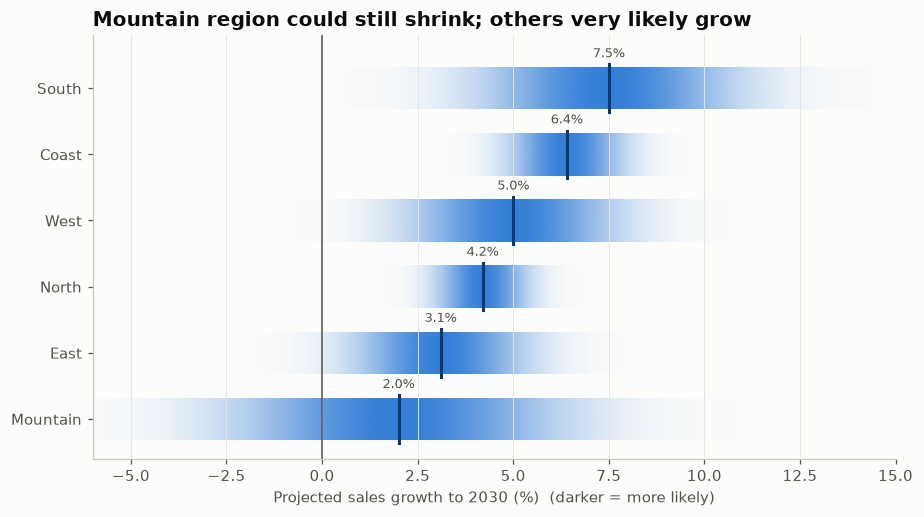

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
xs = np.linspace(-6, 15, 600)
rgb = np.array(to_rgb(PALETTE[0]))
for i, r in enumerate(df.itertuples()):
    dens = stats.norm.pdf(xs, r.mean_growth, r.sd)
    alpha = dens / dens.max()
    img = np.zeros((1, len(xs), 4))
    img[0, :, :3] = rgb
    img[0, :, 3] = alpha * 0.95
    ax.imshow(img, extent=(xs[0], xs[-1], i - 0.32, i + 0.32), aspect="auto", interpolation="bilinear")
    ax.plot([r.mean_growth] * 2, [i - 0.36, i + 0.36], color="#0d366b", lw=2)
    ax.text(r.mean_growth, i + 0.42, f"{r.mean_growth:.1f}%", ha="center", va="bottom",
            fontsize=8.5, color="#52514e")
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(range(len(df)), df["region"])
ax.set_ylim(-0.6, len(df) - 0.2)
ax.set_xlim(-6, 15)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Projected sales growth to 2030 (%)  (darker = more likely)")
ax.set_title("Mountain region could still shrink; others very likely grow")
fig.tight_layout()
plt.show()

## How to read it

Darker means more likely. The North and Coast estimates are tight; the Mountain region is the most uncertain and has real probability of shrinking (the faint band crosses zero). The South has the highest central estimate, but its band overlaps heavily with the Coast's.

---
Standalone script: [`gradient_interval.py`](gradient_interval.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)